##### How large is Pakistan's agriculture financing market, who is currently serving it, where is financing demand concentrated, and where can a Digital Retail Bank participate?

# Pakistan Agriculture Lending Opportunity Analysis

### Sizing Pakistan's Agriculture Financing Market and Identifying Opportunities for a Digital Retail Bank (DRB)

**Prepared by:** Zujaja  
**Tools Used:** Python, Pandas, NumPy, Plotly, Power BI

## Project Overview

This project analyses Pakistan's agricultural lending market to identify where a **Digital Retail Bank (DRB)** can participate.

The analysis begins with an Excel workbook containing bank-wise agricultural finance data and provincial agriculture data. Using Python, the data was cleaned, validated and enriched with derived features such as market share, agriculture's share of bank lending, CAGR, a provincial **Demand Index** and a **DRB Opportunity Score**. The processed data was exported as **ready-to-visualize CSV datasets**, which power an interactive Streamlit dashboard and the accompanying report.

## Dataset Note

This project uses a custom-built dataset developed for analytical purposes.

- **Bank-wise agricultural credit disbursement** is taken from the State Bank of Pakistan's agricultural credit reports, on a **fiscal-year basis** (e.g. 2025 = July 2024 to June 2025).
- Since province-wise lending data is not publicly available, provincial demand is measured through **proxy indicators** (farms, agricultural workforce, cultivated area and crop output).
- Some provincial variables, such as the estimated number of agricultural employees, farms and average farm size, were calculated using **reasonable assumptions and growth rates** based on publicly available data.

The dataset covers **39 banks** across **6 bank categories** and **4 provinces** for **2020–2025**. It is intended to support exploratory analysis and demonstrate a data-driven approach to identifying agricultural lending opportunities, rather than to represent official statistics. 

## Dataset Overview

The original workbook (**Raw Data 1.xlsx**) consists of four worksheets that were cleaned, processed and combined for analysis and visualization.

### Sheet 1: Agri-data
Province-level agriculture and demographic information for 2020–2025.

| Column | Description |
|--------|-------------|
| **Year** | Analysis year (2020–2025). |
| **Province** | Punjab, Sindh, Khyber Pakhtunkhwa or Balochistan. |
| **Population** | Provincial population for the corresponding year. |
| **Estimated Number of Employees** | Estimated agricultural workforce. |
| **Agriculture – Provincial GDP Contribution (%)** | Agriculture's share of the provincial economy. |
| **Agricultural Share of Employment (%)** | Share of employment in agriculture. |
| **Estimated Number of Farms** | Estimated number of farms in the province. |
| **Estimated Avg. Farm Size (Acres)** | Estimated average farm size. |

---

### Sheet 2: Bank Wise Agri finance Data
Bank-level lending information for 39 banks, 2020–2025.

| Column | Description |
|--------|-------------|
| **Year** | Analysis year (2020–2025). |
| **Bank** | Name of the bank. |
| **Bank Type** | Conventional + Islamic, Full Islamic, Foreign Commercial, Microfinance, Digital or Specialized. |
| **Total Advances (PKR Bn)** | Bank's total loan book. |
| **Agricultural Credit Disbursement (PKR Bn)** | New agricultural lending during the year (SBP data). |
| **Agriculture Gross Advances (PKR Bn)** | Outstanding agricultural loans at year end. |

---

### Sheet 3: Output-data
Each province's share of national agricultural output: **crop, livestock and fisheries output (%)**, along with agriculture's GDP contribution and the employment rate.

---

### Sheet 4: Crops Data
Cultivated area (acres) by **province and crop**. This is a single snapshot with no year dimension.

The worksheets were cleaned, merged and transformed using Python to create **ready-to-visualize CSV datasets** for the dashboard.

## Data Preparation & Analysis Workflow

The analysis follows a structured workflow:

1. Load the original Excel workbook and its worksheets.
2. Inspect dataset structure, missing values, duplicates and data types.
3. Validate categories (provinces, bank types, banks) and years.
4. Create derived features (employee growth, employees per farm, agri shares, market share).
5. Analyse market size and growth (totals, YoY growth, CAGR).
6. Analyse who serves the market (bank types, top lenders, segments).
7. Measure provincial demand (Demand Index, crop concentration).
8. Build the DRB Opportunity Score.
9. Visualize the findings.
10. Export the processed datasets as CSV files for the dashboard.

# Part B: Load & inspect

## Load the Workbook

The original Excel workbook is loaded with Pandas, and its sheet names are listed to confirm the available data.

In [36]:
import pandas as pd

file_path = "Raw Data 1.xlsx"

# Load workbook
xls = pd.ExcelFile(file_path)

# Check sheet names
print(xls.sheet_names)

['Agri-data', 'Bank Wise Agri finance Data', 'Output-data', 'Crops Data', 'Formulas']


#### Outcome

The workbook was loaded successfully. It contains the sheets **Agri-data, Bank Wise Agri finance Data, Output-data, Crops Data** and **Formulas**.

## Load the Datasets

Each worksheet is loaded into its own DataFrame: `agri_df` (provincial data), `bank_df` (bank data), `output_df` (output shares) and `crops_df` (crop area).

In [37]:
agri_df = pd.read_excel(file_path, sheet_name="Agri-data")

bank_df = pd.read_excel(
    file_path,
    sheet_name="Bank Wise Agri finance Data"
)

output_df = pd.read_excel(
    file_path,
    sheet_name="Output-data"
)

crops_df = pd.read_excel(
    file_path,
    sheet_name="Crops Data"
)



## Load the Datasets

Each worksheet is loaded into its own DataFrame: `agri_df` (provincial data), `bank_df` (bank data), `output_df` (output shares) and `crops_df` (crop area).

## Inspect Dataset Dimensions

The number of rows and columns in each dataset is checked to confirm that all data was loaded correctly.

In [38]:
print("Agri Data:", agri_df.shape)
print("Bank Data:", bank_df.shape)
print("Output Data:", output_df.shape)
print("Crops Data:", crops_df.shape)


Agri Data: (24, 8)
Bank Data: (234, 6)
Output Data: (4, 6)
Crops Data: (107, 3)


#### Outcome

| Dataset | Rows | Columns |
|---------|------|---------|
| Agri Data | 24 | 8 |
| Bank Data | 234 | 6 |
| Output Data | 4 | 6 |
| Crops Data | 107 | 3 |

All four datasets were loaded with the expected dimensions (4 provinces × 6 years, and 39 banks × 6 years).

## Check for Missing Values

Each dataset is checked for missing values to ensure the data is complete before analysis.

In [39]:
print("AGRI DATA")
print(agri_df.isnull().sum())

print("\nBANK DATA")
print(bank_df.isnull().sum())

print("\nOUTPUT DATA")
print(output_df.isnull().sum())

print("\nCROPS DATA")
print(crops_df.isnull().sum())


AGRI DATA
Year                                             0
Province                                         0
Population                                       0
Estimated Number of Employees                    0
Agriculture – Provincial GDP Contribution (%)    0
Agricultural Share of Employment (%)             0
Estimated Number of Farms                        0
Estimated Avg. Farm Size (Acres)                 0
dtype: int64

BANK DATA
Year                                         0
Bank                                         0
Bank Type                                    0
Total Advances (PKR Bn)                      0
Agricultural Credit Disbursement (PKR Bn)    0
Agriculture Gross Advances(PKR bn)           0
dtype: int64

OUTPUT DATA
Province                                         0
Crop Output (%)                                  0
Livestock Output (%)                             0
Fisheries Output (%)                             0
Agriculture – Provincial GDP Contribution (%) 

## Check for Duplicate Records

Each dataset is checked for duplicate rows that could distort totals and averages.

In [41]:
print("Agri duplicates:", agri_df.duplicated().sum())
print("Bank duplicates:", bank_df.duplicated().sum())
print("Output duplicates:", output_df.duplicated().sum())
print("Crops duplicates:", crops_df.duplicated().sum())

Agri duplicates: 0
Bank duplicates: 0
Output duplicates: 0
Crops duplicates: 0


#### Outcome

No duplicate records were found in any dataset.

## Inspect Data Types

The data type of each column is reviewed to confirm that numeric fields are stored as numbers and text fields as text.

In [42]:
print("AGRI DATA")
print(agri_df.dtypes)

print("\nBANK DATA")
print(bank_df.dtypes)

print("\nOUTPUT DATA")
print(output_df.dtypes)

print("\nCROPS DATA")
print(crops_df.dtypes)

AGRI DATA
Year                                               int64
Province                                          object
Population                                         int64
Estimated Number of Employees                    float64
Agriculture – Provincial GDP Contribution (%)    float64
Agricultural Share of Employment (%)             float64
Estimated Number of Farms                          int64
Estimated Avg. Farm Size (Acres)                 float64
dtype: object

BANK DATA
Year                                           int64
Bank                                          object
Bank Type                                     object
Total Advances (PKR Bn)                      float64
Agricultural Credit Disbursement (PKR Bn)    float64
Agriculture Gross Advances(PKR bn)           float64
dtype: object

OUTPUT DATA
Province                                          object
Crop Output (%)                                    int64
Livestock Output (%)                              

#### Outcome

All numeric columns are stored as **int64** or **float64**, and text columns (Province, Bank, Bank Type, Crop) as **object**. No conversion is required.

## Validate Categories

The unique provinces, bank types and banks are listed to check for spelling inconsistencies or unexpected categories.

In [43]:
print("Agri Provinces:")
print(agri_df["Province"].unique())

print("\nBank Types:")
print(bank_df["Bank Type"].unique())

print("\nBanks:")
print(bank_df["Bank"].unique())

print("\nCrop Provinces:")
print(crops_df["Province"].unique())

Agri Provinces:
['Sindh' 'Punjab' 'Khayber Pakhtunkhuwa' 'Balochistan']

Bank Types:
['Conventional + Islamic Banking' 'Full Islamic' 'Foreign Commercial'
 'Microfinance Bank' 'Digital Bank' 'Specialized Bank']

Banks:
['Habib Bank Limited (HBL)' 'United Bank Limited (UBL)' 'MCB Bank Limited'
 'Allied Bank Limited (ABL)' 'National Bank of Pakistan (NBP)'
 'Bank Alfalah Limited' 'Bank AL Habib Limited' 'Askari Bank Limited'
 'Habib Metropolitan Bank Limited' 'JS Bank Limited' 'Soneri Bank Limited'
 'Standard Chartered Bank (Pakistan) Limited' 'Bank of Punjab (BOP)'
 'Bank of Khyber (BOK)' 'Sindh Bank Limited' 'First Women Bank Limited'
 'Meezan Bank Limited' 'BankIslami Pakistan Limited'
 'Dubai Islamic Bank Pakistan Limited' 'Al Baraka Bank (Pakistan) Limited'
 'Faysal Bank Limited' 'Bank Makramah Limited' 'Citibank N.A. Pakistan'
 'Deutsche Bank AG Pakistan'
 'Industrial and Commercial Bank of China (ICBC) Pakistan'
 'Bank of China Pakistan' 'U Microfinance Bank Limited (UBank)'
 'Mob

#### Outcome

- **4 provinces:** Punjab, Sindh, Khyber Pakhtunkhwa and Balochistan
- **6 bank types:** Conventional + Islamic Banking, Full Islamic, Foreign Commercial, Microfinance Bank, Digital Bank and Specialized Bank
- **39 banks**

Province names are consistent across the Agri and Crops datasets.

## Validate Years

The years in the provincial and bank datasets are checked to confirm that both cover the same period.

In [44]:
print("Agri Years:")
print(sorted(agri_df["Year"].unique()))

print("\nBank Years:")
print(sorted(bank_df["Year"].unique()))

Agri Years:
[np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Bank Years:
[np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


#### Outcome

Both datasets cover **2020–2025**, so they can be compared year by year.

# Part C: Feature engineering

## Calculate Agricultural Employee Growth

The year-on-year growth in agricultural employees is calculated for each province.

In [45]:
agri_df = agri_df.sort_values(["Province", "Year"])

agri_df["Employee Growth (%)"] = (
    agri_df.groupby("Province")["Estimated Number of Employees"]
    .pct_change() * 100
).round(2)

In [46]:
agri_df[
    ["Year", "Province", "Estimated Number of Employees", "Employee Growth (%)"]
]

,Year,Province,Estimated Number of Employees,Employee Growth (%)
18,2020,Balochistan,2.098046e+06,NaN
19,2021,Balochistan,2.418774e+06,15.29
20,2022,Balochistan,2.228557e+06,-7.86
21,2023,Balochistan,2.075475e+06,-6.87
22,2024,Balochistan,2.218853e+06,6.91
23,2025,Balochistan,2.308048e+06,4.02
12,2020,Khayber Pakhtunkhuwa,5.341730e+06,NaN
13,2021,Khayber Pakhtunkhuwa,5.504314e+06,3.04
14,2022,Khayber Pakhtunkhuwa,6.575885e+06,19.47
15,2023,Khayber Pakhtunkhuwa,6.489582e+06,-1.31


#### Outcome

The **Employee Growth (%)** column was added. Values for 2020 are blank because there is no prior year to compare with.

## Calculate Employees per Farm

The number of agricultural workers per farm is calculated for each province and year, indicating the labour intensity of farming.

In [47]:
agri_df["Employees per Farm"] = (
    agri_df["Estimated Number of Employees"]
    / agri_df["Estimated Number of Farms"]
).round(2)

In [48]:
agri_df[
    [
        "Year",
        "Province",
        "Estimated Number of Employees",
        "Estimated Number of Farms",
        "Employees per Farm"
    ]
]

,Year,Province,Estimated Number of Employees,Estimated Number of Farms,Employees per Farm
18,2020,Balochistan,2.098046e+06,538734,3.89
19,2021,Balochistan,2.418774e+06,560963,4.31
20,2022,Balochistan,2.228557e+06,584109,3.82
21,2023,Balochistan,2.075475e+06,608211,3.41
22,2024,Balochistan,2.218853e+06,633307,3.50
23,2025,Balochistan,2.308048e+06,659439,3.50
12,2020,Khayber Pakhtunkhuwa,5.341730e+06,3137024,1.70
13,2021,Khayber Pakhtunkhuwa,5.504314e+06,3368391,1.63
14,2022,Khayber Pakhtunkhuwa,6.575885e+06,3616821,1.82
15,2023,Khayber Pakhtunkhuwa,6.489582e+06,3883573,1.67


#### Outcome

The **Employees per Farm** column was successfully added to the dataset.

## Calculate Agriculture's Share of Bank Lending

Two ratios are calculated for each bank:
- **Agri Disbursement Share (%)** = agricultural disbursement ÷ total advances
- **Agri Gross Advances Share (%)** = outstanding agricultural loans ÷ total advances

These show how important agriculture is within each bank's loan book.

In [49]:
bank_df["Agri Disbursement Share (%)"] = (
    bank_df["Agricultural Credit Disbursement (PKR Bn)"]
    / bank_df["Total Advances (PKR Bn)"]
    * 100
).round(2)

In [50]:
bank_df["Agri Gross Advances Share (%)"] = (
    bank_df["Agriculture Gross Advances(PKR bn)"]
    / bank_df["Total Advances (PKR Bn)"]
    * 100
).round(2)

In [51]:
bank_df[
    bank_df["Year"] == 2025
][
    [
        "Year",
        "Bank",
        "Agri Disbursement Share (%)",
        "Agri Gross Advances Share (%)",

    ]
].sort_values("Bank")

,Year,Bank,Agri Disbursement Share (%),Agri Gross Advances Share (%)
191,2025,ABHI Microfinance Bank Limited,51.28,39.59
215,2025,APNA Microfinance Bank Limited,63.16,18.67
119,2025,Al Baraka Bank (Pakistan) Limited,7.69,2.85
23,2025,Allied Bank Limited (ABL),17.57,4.46
47,2025,Askari Bank Limited,11.64,1.70
41,2025,Bank AL Habib Limited,14.89,3.18
35,2025,Bank Alfalah Limited,7.91,2.09
131,2025,Bank Makramah Limited,2.62,0.00
155,2025,Bank of China Pakistan,NaN,NaN
83,2025,Bank of Khyber (BOK),7.70,0.00


#### Outcome

Both share columns were added. The 2025 view shows how agriculture's importance varies widely across banks.

## Average Agricultural Focus by Bank (2020–2025)

Each bank's agri shares are averaged over 2020–2025 to identify the banks most focused on agriculture.

In [52]:
bank_avg = (
    bank_df[
        bank_df["Year"].between(2020, 2025)
    ]
    .groupby("Bank")[
        [
            "Agri Gross Advances Share (%)",
            "Agri Disbursement Share (%)"
        ]
    ]
    .mean()
    .round(2)
    .reset_index()
    .sort_values("Agri Gross Advances Share (%)", ascending=False)
)

bank_avg

,Bank,Agri Gross Advances Share (%),Agri Disbursement Share (%)
31,Punjab Provincial Cooperative Bank Limited (PP...,100.00,84.36
38,Zarai Taraqiati Bank Limited (ZTBL),100.00,59.47
29,NRSP Microfinance Bank Limited,70.17,58.47
33,Sindh Microfinance Bank Limited,64.39,15.69
24,Khushhali Microfinance Bank Limited,61.00,65.55
18,HBL Microfinance Bank,57.82,37.66
28,Mobilink Microfinance Bank Limited (JazzCash),52.13,49.20
36,U Microfinance Bank Limited (UBank),46.33,62.92
0,ABHI Microfinance Bank Limited,37.04,45.66
1,APNA Microfinance Bank Limited,30.06,43.57


#### Outcome

Specialized and microfinance banks (**PPCBL, ZTBL, NRSP Microfinance Bank, Sindh Microfinance Bank**) have the highest agricultural focus, while large commercial banks lend the most in absolute terms despite a small agri share. ZTBL holds the largest average agricultural gross advances.

In [53]:
bank_avg = (
    bank_df[
        bank_df["Year"].between(2020, 2025)
    ]
    .groupby("Bank")[
        [
            "Agriculture Gross Advances(PKR bn)",
            "Agri Gross Advances Share (%)",
            "Agri Disbursement Share (%)"
        ]
    ]
    .mean()
    .round(2)
    .reset_index()
    .sort_values(
        "Agriculture Gross Advances(PKR bn)",
        ascending=False
    )
)

bank_avg

,Bank,Agriculture Gross Advances(PKR bn),Agri Gross Advances Share (%),Agri Disbursement Share (%)
38,Zarai Taraqiati Bank Limited (ZTBL),123.69,100.00,59.47
30,National Bank of Pakistan (NBP),113.55,7.52,18.54
3,Allied Bank Limited (ABL),107.27,14.64,13.13
19,Habib Bank Limited (HBL),106.03,5.47,14.61
16,Faysal Bank Limited,66.45,10.99,4.26
10,Bank of Punjab (BOP),54.62,7.59,8.36
27,Meezan Bank Limited,52.80,3.52,4.86
18,HBL Microfinance Bank,44.43,57.82,37.66
24,Khushhali Microfinance Bank Limited,43.43,61.00,65.55
28,Mobilink Microfinance Bank Limited (JazzCash),33.93,52.13,49.20


## Define Helper Variables

Short names are defined for the long column names, along with a **CAGR** function used throughout the analysis:

CAGR = (End value ÷ Start value)^(1 ÷ Years) − 1

In [54]:
# Short names for long column names
TA    = "Total Advances (PKR Bn)"
DISB  = "Agricultural Credit Disbursement (PKR Bn)"
GROSS = "Agriculture Gross Advances(PKR bn)"

def cagr(start, end, years):
    return ((end / start) ** (1 / years) - 1) * 100

## Merge Duplicate Crop Records

After standardizing crop names, some province-crop combinations appeared more than once. These rows are combined so that each province-crop pair appears only once.

In [55]:
# Merge duplicate Province-Crop rows (safe to run more than once)
area_col = [c for c in crops_df.columns if c.startswith("Cultivated Area")][0]
crops_df = (
    crops_df.groupby(["Province", "Crop"], as_index=False)[area_col].sum()
    .rename(columns={area_col: "Cultivated Area (Acres)"})
)
print("Crops rows:", crops_df.shape[0], "| Duplicates:", crops_df.duplicated(["Province", "Crop"]).sum())

Crops rows: 107 | Duplicates: 0


#### Outcome

The crops dataset contains **107 rows** with **no duplicate province-crop pairs**.

## Build the Provincial Profile (2025)

Provincial data for the latest year is combined with output shares and cultivated area. Each province's share of national farms, agricultural employees and cultivated area is then calculated.

In [56]:
# Province profile (latest year)
latest = agri_df[agri_df["Year"] == agri_df["Year"].max()].copy()
area_by_prov = crops_df.groupby("Province")["Cultivated Area (Acres)"].sum()

prov = (
    latest[["Province", "Population", "Estimated Number of Employees", "Estimated Number of Farms",
            "Estimated Avg. Farm Size (Acres)", "Agriculture – Provincial GDP Contribution (%)"]]
    .merge(output_df[["Province", "Crop Output (%)", "Livestock Output (%)", "Fisheries Output (%)"]], on="Province")
    .set_index("Province")
)
prov["Cultivated Area (Acres)"] = area_by_prov

for col in ["Estimated Number of Employees", "Estimated Number of Farms", "Cultivated Area (Acres)"]:
    prov[f"{col} – Share (%)"] = (prov[col] / prov[col].sum() * 100).round(1)

prov

,Population,Estimated Number of Employees,Estimated Number of Farms,Estimated Avg. Farm Size (Acres),Agriculture – Provincial GDP Contribution (%),Crop Output (%),Livestock Output (%),Fisheries Output (%),Cultivated Area (Acres),Estimated Number of Employees – Share (%),Estimated Number of Farms – Share (%),Cultivated Area (Acres) – Share (%)
Province,,,,,,,,,,,,
Balochistan,15860475,2.308048e+06,659439,15.68,25.01,8,17,15,2662650,4.6,5.5,4.4
Khayber Pakhtunkhuwa,42638375,8.254789e+06,4477552,2.04,22.70,12,13,8,3860650,16.6,37.1,6.3
Punjab,134191023,3.073801e+07,5054574,6.14,20.02,56,43,20,42630237,61.9,41.8,69.7
Sindh,58585829,8.345551e+06,1891915,4.80,23.54,24,27,57,11967241,16.8,15.7,19.6


#### Outcome

| Province | Share of farms | Share of agri workers | Share of cultivated area |
|----------|----------------|-----------------------|--------------------------|
| Punjab | 41.8% | 61.9% | 69.7% |
| Khyber Pakhtunkhwa | 37.1% | 16.6% | 6.3% |
| Sindh | 15.7% | 16.8% | 19.6% |
| Balochistan | 5.5% | 4.6% | 4.4% |

## Calculate Disbursement Market Share

Each bank's share of the whole market's agricultural disbursement is calculated for every year.

In [101]:
# Disbursement market share: bank disbursement / total industry disbursement in that year
bank_df["Disbursement Market Share (%)"] = (
    bank_df[DISB] / bank_df.groupby("Year")[DISB].transform("sum") * 100
).round(2)

#### Outcome

The **Disbursement Market Share (%)** column was successfully added to the dataset.

# Part D: Market size

### How Large Is the Market?

Total advances, agricultural disbursement and agricultural gross advances are summed for each year, along with year-on-year growth and agriculture's share of total advances.

In [102]:
# Market size: Yearly Totals
market = bank_df.groupby("Year")[[TA, DISB, GROSS]].sum(min_count=1).round(1)
market["Disbursement YoY (%)"]       = (market[DISB].pct_change() * 100).round(1)
market["Gross Advances YoY (%)"]     = (market[GROSS].pct_change() * 100).round(1)
market["Agri Share of Advances (%)"] = (market[GROSS] / market[TA] * 100).round(2)
market

,Total Advances (PKR Bn),Agricultural Credit Disbursement (PKR Bn),Agriculture Gross Advances(PKR bn),Disbursement YoY (%),Gross Advances YoY (%),Agri Share of Advances (%)
Year,,,,,,
2020,8983.1,1183.8,669.1,NaN,NaN,7.45
2021,11251.7,1340.7,709.5,13.3,6.0,6.31
2022,12861.5,1390.8,772.1,3.7,8.8,6.00
2023,14088.9,1743.5,1052.5,25.4,36.3,7.47
2024,17086.6,2184.7,988.2,25.3,-6.1,5.78
2025,18886.6,2542.6,1328.4,16.4,34.4,7.03


#### Outcome

Agricultural disbursement grew every year, from **PKR 1,183.8 bn (2020)** to **PKR 2,542.6 bn (2025)**. Agriculture's share of total advances moved from **7.45% to 7.03%**.

## Calculate Growth Rates (CAGR)

The compound annual growth rate is calculated for disbursement, gross advances and total advances over 2020–2025.

In [59]:
y0, y1 = market.index.min(), market.index.max()
n = y1 - y0

for label, col in [("Agri Disbursement", DISB), ("Agri Gross Adv.", GROSS), ("Total Advances", TA)]:
    print(f"{label:18}: {market.loc[y0, col]:,.0f} bn -> {market.loc[y1, col]:,.0f} bn | CAGR {cagr(market.loc[y0, col], market.loc[y1, col], n):.1f}%")

Agri Disbursement : 1,184 bn -> 2,543 bn | CAGR 16.5%
Agri Gross Adv.   : 669 bn -> 1,328 bn | CAGR 14.7%
Total Advances    : 8,983 bn -> 18,887 bn | CAGR 16.0%


#### Outcome

| Measure | 2020 | 2025 | CAGR |
|---------|------|------|------|
| Agri disbursement | PKR 1,184 bn | PKR 2,543 bn | **16.5%** |
| Agri gross advances | PKR 669 bn | PKR 1,328 bn | **14.7%** |
| Total advances | PKR 8,983 bn | PKR 18,887 bn | **16.0%** |

Agricultural lending is growing at roughly the same pace as overall bank lending.

# Part E: Who serves the market

### Share by Bank Type

Each bank type's share of total agricultural disbursement is calculated for every year.

In [103]:
# Disbursement share by bank type
type_disb  = bank_df.pivot_table(index="Year", columns="Bank Type", values=DISB, aggfunc="sum")
type_share = (type_disb.div(type_disb.sum(axis=1), axis=0) * 100).round(2)
type_share

Bank Type,Conventional + Islamic Banking,Digital Bank,Foreign Commercial,Full Islamic,Microfinance Bank,Specialized Bank
Year,,,,,,
2020,76.50,0.27,0.0,5.73,11.49,6.01
2021,79.00,0.07,0.0,4.70,9.76,6.47
2022,75.81,0.14,0.0,5.31,13.22,5.52
2023,77.01,0.09,0.0,5.78,12.30,4.81
2024,78.57,0.07,0.0,7.47,9.83,4.06
2025,78.54,0.05,0.0,8.16,9.89,3.37


#### Outcome

Conventional + Islamic banks dominate, with **78.5%** of disbursement in 2025. Microfinance banks' share fell from 11.5% to 9.9%, and digital banks hold only **0.05%**.

## Growth by Bank Type

Disbursement in 2020 and 2025 is compared for each bank type, along with its CAGR.

In [104]:
# Growth by bank type
type_growth = pd.DataFrame({
    f"Disb {y0} (bn)": type_disb.loc[y0].round(1),
    f"Disb {y1} (bn)": type_disb.loc[y1].round(1),
})
type_growth["CAGR (%)"] = [
    round(cagr(a, b, n), 1) if a > 0 else None
    for a, b in zip(type_growth.iloc[:, 0], type_growth.iloc[:, 1])
]
type_growth.sort_values(f"Disb {y1} (bn)", ascending=False)

,Disb 2020 (bn),Disb 2025 (bn),CAGR (%)
Bank Type,,,
Conventional + Islamic Banking,905.6,1996.9,17.1
Microfinance Bank,136.0,251.5,13.1
Full Islamic,67.9,207.5,25.0
Specialized Bank,71.1,85.6,3.8
Digital Bank,3.2,1.2,-17.8
Foreign Commercial,0.0,0.0,NaN


#### Outcome

**Full Islamic banks are the fastest-growing group (25.0% CAGR)**, while microfinance and specialized banks grew more slowly than the market.

## Top 10 Agricultural Lenders (2025)

The ten largest lenders by agricultural disbursement are ranked, with their market share and cumulative share.

In [62]:
# Top 10 lenders (latest year)
top10 = (
    bank_df[bank_df["Year"] == y1]
    .sort_values(DISB, ascending=False)
    [["Bank", "Bank Type", DISB, "Disbursement Market Share (%)", GROSS]]
    .head(10)
    .reset_index(drop=True)
)
top10["Cumulative Share (%)"] = top10["Disbursement Market Share (%)"].cumsum().round(2)
top10.index = top10.index + 1
top10

,Bank,Bank Type,Agricultural Credit Disbursement (PKR Bn),Disbursement Market Share (%),Agriculture Gross Advances(PKR bn),Cumulative Share (%)
1,Habib Bank Limited (HBL),Conventional + Islamic Banking,455.56,17.92,160.00,17.92
2,National Bank of Pakistan (NBP),Conventional + Islamic Banking,374.17,14.72,132.60,32.64
3,United Bank Limited (UBL),Conventional + Islamic Banking,255.57,10.05,24.85,42.69
4,MCB Bank Limited,Conventional + Islamic Banking,216.27,8.51,12.70,51.20
5,Allied Bank Limited (ABL),Conventional + Islamic Banking,140.90,5.54,35.80,56.74
6,Bank of Punjab (BOP),Conventional + Islamic Banking,132.83,5.22,132.02,61.96
7,Bank AL Habib Limited,Conventional + Islamic Banking,117.95,4.64,25.18,66.60
8,Meezan Bank Limited,Full Islamic,108.14,4.25,212.82,70.85
9,Bank Alfalah Limited,Conventional + Islamic Banking,91.02,3.58,24.05,74.43
10,Zarai Taraqiati Bank Limited (ZTBL),Specialized Bank,72.98,2.87,140.80,77.30


#### Outcome

**HBL** is the largest lender (PKR 455.6 bn, 17.9%), followed by **NBP** (14.7%) and **UBL** (10.1%). The top 5 lenders hold **56.7%** of the market and the top 10 hold **77.3%**.

# Part F: Demand

### Provincial Demand Index

Since province-wise lending data is not available, a **Demand Index** combines four proxy indicators using assumed weights:

| Indicator | Weight |
|-----------|--------|
| Share of farms | 30% |
| Share of agricultural employees | 20% |
| Share of cultivated area | 25% |
| Share of crop output | 25% |

#### Outcome

| Province | Demand Index | Rank |
|----------|--------------|------|
| Punjab | 56.3 | 1 |
| Khyber Pakhtunkhwa | 19.0 | 2 |
| Sindh | 19.0 | 2 |
| Balochistan | 5.7 | 4 |

Punjab is the centre of agricultural financing demand.

In [105]:
# Demand Index (weights are assumptions and can be adjusted)
weights = {
    "Estimated Number of Farms – Share (%)": 0.30,
    "Estimated Number of Employees – Share (%)": 0.20,
    "Cultivated Area (Acres) – Share (%)": 0.25,
    "Crop Output (%)": 0.25,
}
prov["Demand Index"] = sum(prov[c] * wgt for c, wgt in weights.items()).round(1)
prov["Demand Rank"] = prov["Demand Index"].rank(ascending=False).astype(int)

prov[list(weights) + ["Demand Index", "Demand Rank"]].sort_values("Demand Rank")

,Estimated Number of Farms – Share (%),Estimated Number of Employees – Share (%),Cultivated Area (Acres) – Share (%),Crop Output (%),Demand Index,Demand Rank
Province,,,,,,
Punjab,41.8,61.9,69.7,56,56.3,1
Khayber Pakhtunkhuwa,37.1,16.6,6.3,12,19.0,2
Sindh,15.7,16.8,19.6,24,19.0,2
Balochistan,5.5,4.6,4.4,8,5.7,4


## Crop Concentration

The share of national cultivated area held by each crop is calculated, along with the top three crops in each province.

In [106]:
# Crop concentration
nat_crops = crops_df.groupby("Crop")["Cultivated Area (Acres)"].sum().sort_values(ascending=False)
nat_crops_share = (nat_crops / nat_crops.sum() * 100).round(1)
print(f"Share of Top 5 crops: {nat_crops_share.head(5).sum():.1f}% of cultivated area")
display(pd.DataFrame({"Acres": nat_crops, "Share (%)": nat_crops_share}).head(10))

top3 = (crops_df.sort_values("Cultivated Area (Acres)", ascending=False)
        .groupby("Province").head(3)
        .sort_values(["Province", "Cultivated Area (Acres)"], ascending=[True, False]))
top3

Share of Top 5 crops: 82.9% of cultivated area


,Acres,Share (%)
Crop,,
Wheat,28762000,47.1
Rice,10109000,16.5
Cotton,5810000,9.5
Maize,3371475,5.5
Sugarcane,2629896,4.3
Chickpeas,1802100,2.9
Berseem,1650000,2.7
Sorghum,1402000,2.3
Potatoes,583600,1.0


,Province,Crop,Cultivated Area (Acres)
27,Balochistan,Wheat,945000
21,Balochistan,Rice,464000
22,Balochistan,Sorghum,282000
54,Khayber Pakhtunkhuwa,Wheat,1815000
36,Khayber Pakhtunkhuwa,Maize,1145000
49,Khayber Pakhtunkhuwa,Sugarcane,252000
83,Punjab,Wheat,20653000
78,Punjab,Rice,6674000
61,Punjab,Cotton,3833000
106,Sindh,Wheat,5349000


#### Outcome

The **top 5 crops cover 82.9%** of cultivated area. Wheat alone accounts for 47.1%, followed by rice (16.5%) and cotton (9.5%), so crop lending follows the Rabi and Kharif seasons.

# Part G: DRB opportunity

### DRB Opportunity: Credit Intensity

Average agricultural credit per farm and per cultivated acre is calculated for 2025.

In [107]:
# Credit per farm and per acre (latest year)
total_disb_pkr = market.loc[y1, DISB] * 1e9
total_farms    = latest["Estimated Number of Farms"].sum()
total_acres    = crops_df["Cultivated Area (Acres)"].sum()

print(f"Total farms           : {total_farms:,.0f}")
print(f"Disbursement per farm : PKR {total_disb_pkr / total_farms:,.0f}")
print(f"Disbursement per acre : PKR {total_disb_pkr / total_acres:,.0f} ")

Total farms           : 12,083,480
Disbursement per farm : PKR 210,420
Disbursement per acre : PKR 41,600 


#### Outcome

- Total farms: **12,083,480**
- Disbursement per farm: **PKR 210,420**
- Disbursement per acre: **PKR 41,600**

## The Small-Ticket Segment: MFB + Digital Banks

Microfinance and digital banks, the segment a DRB would compete in, are compared with the rest of the market.

In [66]:
# MFB + Digital segment vs rest of the market
seg_map = {"Microfinance Bank": "MFB + Digital", "Digital Bank": "MFB + Digital"}
bank_df["Segment"] = bank_df["Bank Type"].map(seg_map).fillna("Commercial / Islamic / Specialized")

seg = bank_df.groupby(["Year", "Segment"])[DISB].sum().unstack()
seg_share = (seg.div(seg.sum(axis=1), axis=0) * 100).round(2)
nbanks = bank_df[bank_df["Year"] == y1].groupby("Segment")["Bank"].nunique()

seg_summary = pd.DataFrame({
    f"Disb {y1} (bn)": seg.loc[y1].round(1),
    f"Share {y1} (%)": seg_share.loc[y1],
    "CAGR (%)": [round(cagr(seg.loc[y0, s], seg.loc[y1, s], n), 1) for s in seg.columns],
    "No. of banks": nbanks,
})
seg_summary["Avg Disb per Bank (bn)"] = (seg_summary[f"Disb {y1} (bn)"] / seg_summary["No. of banks"]).round(1)
seg_summary

,Disb 2025 (bn),Share 2025 (%),CAGR (%),No. of banks,Avg Disb per Bank (bn)
Segment,,,,,
Commercial / Islamic / Specialized,2290.0,90.06,17.0,28,81.8
MFB + Digital,252.6,9.94,12.7,11,23.0


## DRB Opportunity Score

Each province is scored from 0 to 100 using six equally weighted factors. Each factor is scaled relative to the top-performing province (max normalization), and smaller average farm size scores higher because it suits small-ticket digital lending.

**Levels:** High ≥ 70 · Medium 40–70 · Low < 40

In [108]:
# DRB Opportunity Score (0-100 index) + Level -- 6 factors
opp = latest.set_index("Province")[[
    "Estimated Number of Employees",
    "Agriculture – Provincial GDP Contribution (%)",
    "Agricultural Share of Employment (%)",
    "Estimated Number of Farms",
    "Estimated Avg. Farm Size (Acres)",
]].copy()
opp["Cultivated Area (Acres)"] = crops_df.groupby("Province")["Cultivated Area (Acres)"].sum()

# 1. Scale each factor to 0-100: best province = 100 (max normalization)
higher_is_better = [
    "Estimated Number of Employees",
    "Agriculture – Provincial GDP Contribution (%)",
    "Agricultural Share of Employment (%)",
    "Estimated Number of Farms",
    "Cultivated Area (Acres)",
]
for col in higher_is_better:
    opp[f"{col} Index"] = opp[col] / opp[col].max() * 100

# Farm size: smaller farms = small-ticket loans = digital-friendly, so inverse is used
small = 1 / opp["Estimated Avg. Farm Size (Acres)"]
opp["Estimated Avg. Farm Size (Acres) Index"] = small / small.max() * 100

# 2. 2. Weights (currently equal at 1/6 each; must add up to 1)
drb_weights = {
    "Estimated Number of Employees Index": 1/6,
    "Agriculture – Provincial GDP Contribution (%) Index": 1/6,
    "Agricultural Share of Employment (%) Index": 1/6,
    "Estimated Number of Farms Index": 1/6,
    "Estimated Avg. Farm Size (Acres) Index": 1/6,
    "Cultivated Area (Acres) Index": 1/6,
}
opp["DRB Opportunity Score"] = sum(opp[c] * wgt for c, wgt in drb_weights.items()).round(1)

# 3. Level
opp["DRB Opportunity Level"] = pd.cut(
    opp["DRB Opportunity Score"],
    bins=[0, 40, 70, 100],
    labels=["Low", "Medium", "High"],
    include_lowest=True,
)
opp["Rank"] = opp["DRB Opportunity Score"].rank(ascending=False).astype(int)

index_cols = list(drb_weights)
opp[index_cols] = opp[index_cols].round(1)
opp = opp.sort_values("Rank")
opp[["Rank", "DRB Opportunity Score", "DRB Opportunity Level"]]

,Rank,DRB Opportunity Score,DRB Opportunity Level
Province,,,
Punjab,1,85.5,High
Khayber Pakhtunkhuwa,2,67.7,Medium
Sindh,3,51.4,Medium
Balochistan,4,36.2,Low


### DRB Opportunity Index: Provincial Ranking

The **DRB Opportunity Index** scores each province from **0 to 100** using six equally weighted factors:

- Number of agricultural employees
- Agriculture's share of provincial GDP
- Agriculture's share of employment
- Number of farms
- Average farm size *(smaller farms score higher)*
- Cultivated area

Each factor is scaled relative to the top-performing province (**max normalization**).

| Rank | Province | Score | Level |
|---|---|---|---|
| 1 | Punjab | 85.5 | High |
| 2 | Khyber Pakhtunkhwa | 67.7 | Medium |
| 3 | Sindh | 51.4 | Medium |
| 4 | Balochistan | 36.2 | Low |

**Key findings**

- **Punjab (85.5, High):** Leads on four of six factors (agricultural workforce, share of employment, number of farms and cultivated area). It is the largest agri-lending market, but also the most competitive.
- **Khyber Pakhtunkhwa (67.7, Medium):** Has the smallest average farm size (2.04 acres) and the second-highest number of farms, which makes it well suited to small-ticket digital lending despite its small cultivated area.
- **Sindh (51.4, Medium):** Agriculture is important to the economy, but Sindh has fewer farms and workers than Punjab and larger farms than KP.
- **Balochistan (36.2, Low):** Agriculture has the highest GDP share, but the small farm base, workforce and cultivated area limit the scale for digital lending.

> **Note:** The score is a relative index, not a probability or market share. GDP and employment shares vary little across provinces and lift all scores, which is why Balochistan falls in the Low band.

# Part H: Final tables & visualizations

## Build the Final Provincial Table (2020–2025)

All provincial calculations (shares, Demand Index, DRB factor indexes and score, and credit per farm) are combined for every year into one table, `final_df`.

In [82]:
# ---------- Province-level table, 2020-2025 ----------

final_df = agri_df.copy()

# Crop, livestock and fisheries output shares
output_cols = ["Province", "Crop Output (%)", "Livestock Output (%)", "Fisheries Output (%)"]
final_df = final_df.merge(output_df[output_cols], on="Province", how="left")

# Cultivated area per province (no year in crops data, so it repeats each year)
area_col = [col for col in crops_df.columns if col.startswith("Cultivated Area")][0]
final_df["Cultivated Area (Acres)"] = final_df["Province"].map(crops_df.groupby("Province")[area_col].sum())

# Each province's share of the national total, within the same year
for col in ["Estimated Number of Employees", "Estimated Number of Farms", "Cultivated Area (Acres)"]:
    year_total = final_df.groupby("Year")[col].transform("sum")
    final_df[f"{col} – Share (%)"] = (final_df[col] / year_total * 100).round(1)

# Demand Index
demand_weights = {
    "Estimated Number of Farms – Share (%)": 0.30,
    "Estimated Number of Employees – Share (%)": 0.20,
    "Cultivated Area (Acres) – Share (%)": 0.25,
    "Crop Output (%)": 0.25,
}
final_df["Demand Index"] = sum(final_df[c] * w for c, w in demand_weights.items()).round(1)
final_df["Demand Rank"] = final_df.groupby("Year")["Demand Index"].rank(ascending=False).astype(int)

# DRB factor indexes: best province in each year = 100
for col in ["Estimated Number of Employees", "Agriculture – Provincial GDP Contribution (%)",
            "Agricultural Share of Employment (%)", "Estimated Number of Farms", "Cultivated Area (Acres)"]:
    final_df[f"{col} Index"] = (final_df[col] / final_df.groupby("Year")[col].transform("max") * 100).round(1)

small = 1 / final_df["Estimated Avg. Farm Size (Acres)"]          # smaller farms score higher
final_df["Estimated Avg. Farm Size (Acres) Index"] = (small / small.groupby(final_df["Year"]).transform("max") * 100).round(1)

index_cols = [c for c in final_df.columns if c.endswith(" Index") and c != "Demand Index"]
final_df["DRB Opportunity Score"] = final_df[index_cols].mean(axis=1).round(1)
final_df["DRB Opportunity Level"] = pd.cut(final_df["DRB Opportunity Score"], bins=[0, 40, 70, 100],
                                           labels=["Low", "Medium", "High"], include_lowest=True).astype(str)
final_df["DRB Rank"] = final_df.groupby("Year")["DRB Opportunity Score"].rank(ascending=False).astype(int)

# Credit per farm: that year's national disbursement / that year's total farms
disb_by_year = bank_df.groupby("Year")["Agricultural Credit Disbursement (PKR Bn)"].sum()
farms_by_year = final_df.groupby("Year")["Estimated Number of Farms"].sum()
final_df["National Disbursement per Farm (PKR)"] = final_df["Year"].map((disb_by_year * 1e9 / farms_by_year).round(0))

final_df = final_df.sort_values(["Year", "DRB Rank"]).reset_index(drop=True)
print(final_df.shape)
final_df

(24, 29)


,Year,Province,Population,Estimated Number of Employees,Agriculture – Provincial GDP Contribution (%),Agricultural Share of Employment (%),Estimated Number of Farms,Estimated Avg. Farm Size (Acres),Employee Growth (%),Employees per Farm,...,Estimated Number of Employees Index,Agriculture – Provincial GDP Contribution (%) Index,Agricultural Share of Employment (%) Index,Estimated Number of Farms Index,Cultivated Area (Acres) Index,Estimated Avg. Farm Size (Acres) Index,DRB Opportunity Score,DRB Opportunity Level,DRB Rank,National Disbursement per Farm (PKR)
0,2020,Punjab,118521695,2.505653e+07,19.00,44.79,5118830,5.95,NaN,4.89,...,100.0,79.2,100.0,100.0,100.0,41.5,86.8,High,1,114037.0
1,2020,Khayber Pakhtunkhuwa,38177031,5.341730e+06,21.85,31.80,3137024,2.47,NaN,1.70,...,21.3,91.0,71.0,61.3,9.1,100.0,59.0,Medium,2,114037.0
2,2020,Sindh,51626658,7.124995e+06,21.90,37.30,1586341,5.88,NaN,4.49,...,28.4,91.2,83.3,31.0,28.1,42.0,50.7,Medium,3,114037.0
3,2020,Balochistan,13554496,2.098046e+06,24.00,40.10,538734,17.74,NaN,3.89,...,8.4,100.0,89.5,10.5,6.2,13.9,38.1,Low,4,114037.0
4,2021,Punjab,121501874,2.626579e+07,19.32,45.80,5105914,5.98,4.83,5.14,...,100.0,80.4,100.0,100.0,100.0,39.6,86.7,High,1,125551.0
5,2021,Khayber Pakhtunkhuwa,39068720,5.504314e+06,21.71,32.02,3368391,2.37,3.04,1.63,...,21.0,90.4,69.9,66.0,9.1,100.0,59.4,Medium,2,125551.0
6,2021,Sindh,52948996,7.385855e+06,23.03,37.70,1643227,5.64,3.66,4.49,...,28.1,95.9,82.3,32.2,28.1,42.0,51.4,Medium,3,125551.0
7,2021,Balochistan,13987173,2.418774e+06,24.02,44.80,560963,17.30,15.29,4.31,...,9.2,100.0,97.8,11.0,6.2,13.7,39.6,Low,4,125551.0
8,2022,Punjab,124556988,2.701442e+07,19.47,45.95,5093030,6.02,2.85,5.30,...,100.0,78.4,100.0,100.0,100.0,38.0,86.1,High,1,126477.0
9,2022,Khayber Pakhtunkhuwa,39960409,6.575885e+06,22.79,37.40,3616821,2.29,19.47,1.82,...,24.3,91.7,81.4,71.0,9.1,100.0,62.9,Medium,2,126477.0


#### Outcome

The final provincial table contains **24 rows** (4 provinces × 6 years) and **29 columns**.

## Prepare the Bank Dataset for Visualization

A clean copy of the bank data is created, with text cleaned and records sorted by bank and year.

In [83]:
# ---------- Raw bank data in its own DataFrame ----------

bank_raw_df = pd.read_excel(file_path, sheet_name="Bank Wise Agri finance Data")

# Remove any extra spaces from text columns
for col in ["Bank", "Bank Type"]:
    bank_raw_df[col] = bank_raw_df[col].str.strip()

bank_raw_df = bank_raw_df.sort_values(["Bank", "Year"]).reset_index(drop=True)

bank_raw_df.to_csv("agri_bank_raw_data.csv", index=False)

print(bank_raw_df.shape)
bank_raw_df

(234, 6)


,Year,Bank,Bank Type,Total Advances (PKR Bn),Agricultural Credit Disbursement (PKR Bn),Agriculture Gross Advances(PKR bn)
0,2020,ABHI Microfinance Bank Limited,Microfinance Bank,21.550,12.64,10.431
1,2021,ABHI Microfinance Bank Limited,Microfinance Bank,19.700,8.55,6.500
2,2022,ABHI Microfinance Bank Limited,Microfinance Bank,17.216,6.28,5.680
3,2023,ABHI Microfinance Bank Limited,Microfinance Bank,18.760,3.69,1.250
4,2024,ABHI Microfinance Bank Limited,Microfinance Bank,20.000,12.89,12.320
...,...,...,...,...,...,...
229,2021,Zarai Taraqiati Bank Limited (ZTBL),Specialized Bank,115.260,78.50,115.260
230,2022,Zarai Taraqiati Bank Limited (ZTBL),Specialized Bank,107.600,69.22,107.600
231,2023,Zarai Taraqiati Bank Limited (ZTBL),Specialized Bank,119.980,75.42,119.980
232,2024,Zarai Taraqiati Bank Limited (ZTBL),Specialized Bank,128.600,79.41,128.600


#### Outcome

The bank dataset contains **234 rows** (39 banks × 6 years) and is ready for visualization.

## Visualizations

Interactive Plotly charts are created to answer the four research questions:

1. How large is the market?
2. Who is serving it?
3. Where is demand concentrated?
4. Where can a Digital Retail Bank participate?

In [84]:
# ---------- Setup for all charts ----------
import plotly.express as px

px.defaults.template = "simple_white"

disb_col = "Agricultural Credit Disbursement (PKR Bn)"
gross_col = "Agriculture Gross Advances(PKR bn)"

latest_year = bank_raw_df["Year"].max()

### Q1. How large is the market?

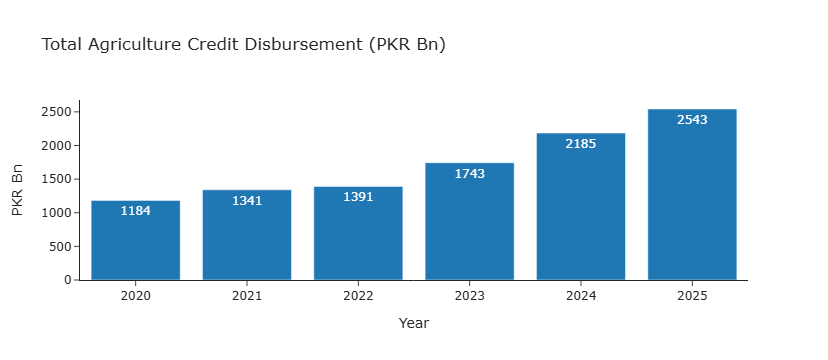

In [85]:
# Q1. Market size: total agri disbursement each year
yearly = bank_raw_df.groupby("Year", as_index=False)[disb_col].sum()

fig = px.bar(
    yearly,
    x="Year",
    y=disb_col,
    text_auto=".0f",
    title="Total Agriculture Credit Disbursement (PKR Bn)",
    labels={disb_col: "PKR Bn"}
)
fig.show()

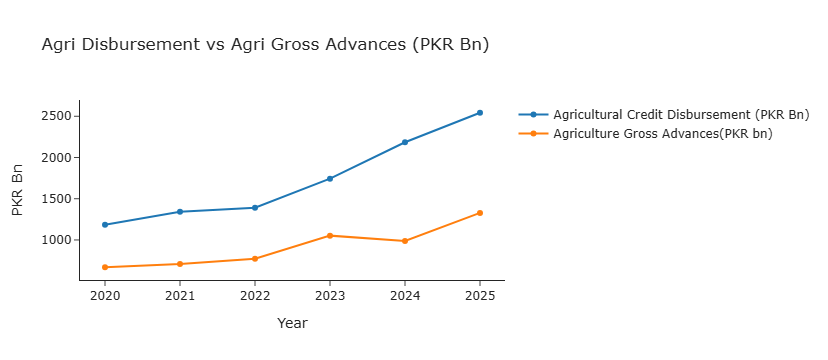

In [86]:
# Q1. Market size: disbursement vs outstanding agri loans
yearly = bank_raw_df.groupby("Year", as_index=False)[[disb_col, gross_col]].sum()

fig = px.line(
    yearly,
    x="Year",
    y=[disb_col, gross_col],
    markers=True,
    title="Agri Disbursement vs Agri Gross Advances (PKR Bn)",
    labels={"value": "PKR Bn", "variable": ""}
)
fig.show()

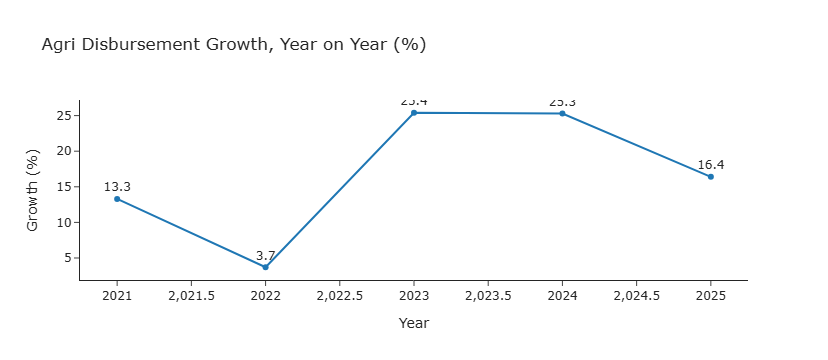

In [87]:
# Q1. Market size: yearly growth of disbursement
yearly = bank_raw_df.groupby("Year", as_index=False)[disb_col].sum()
yearly["Growth (%)"] = (yearly[disb_col].pct_change() * 100).round(1)

fig = px.line(
    yearly.dropna(),
    x="Year",
    y="Growth (%)",
    markers=True,
    text="Growth (%)",
    title="Agri Disbursement Growth, Year on Year (%)"
)

fig.update_traces(
    textposition="top center"
)

fig.show()

### Q2. Who is serving it?

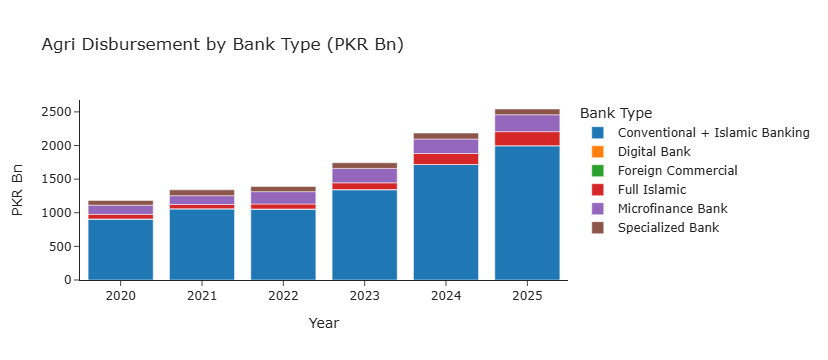

In [88]:
# Q2. Who serves the market: disbursement by bank type each year
by_type = bank_raw_df.groupby(["Year", "Bank Type"], as_index=False)[disb_col].sum()

fig = px.bar(
    by_type,
    x="Year",
    y=disb_col,
    color="Bank Type",
    title="Agri Disbursement by Bank Type (PKR Bn)",
    labels={disb_col: "PKR Bn"}
)
fig.show()

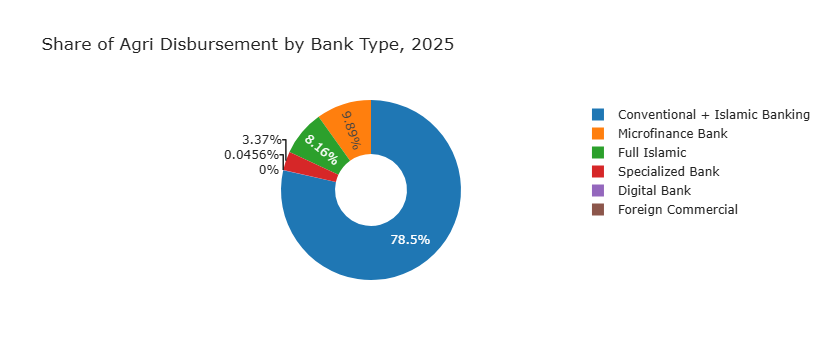

In [89]:
# Q2. Who serves the market: market share by bank type (latest year)
latest_banks = bank_raw_df[bank_raw_df["Year"] == latest_year]
by_type = latest_banks.groupby("Bank Type", as_index=False)[disb_col].sum()

fig = px.pie(
    by_type,
    names="Bank Type",
    values=disb_col,
    hole=0.4,
    title=f"Share of Agri Disbursement by Bank Type, {latest_year}"
)
fig.show()

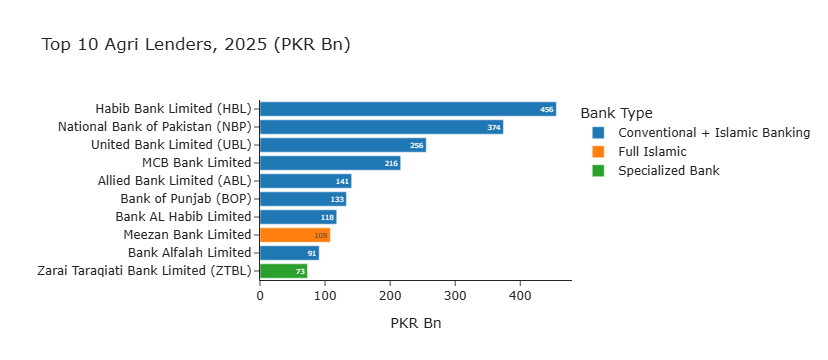

In [90]:
# Q2. Who serves the market: top 10 banks (latest year)
top10 = (
    bank_raw_df[bank_raw_df["Year"] == latest_year]
    .sort_values(disb_col, ascending=False)
    .head(10)
)

fig = px.bar(
    top10,
    x=disb_col,
    y="Bank",
    color="Bank Type",
    orientation="h",
    text_auto=".0f",
    title=f"Top 10 Agri Lenders, {latest_year} (PKR Bn)",
    labels={disb_col: "PKR Bn", "Bank": ""}
)
fig.update_layout(yaxis={"categoryorder": "total ascending"})
fig.show()

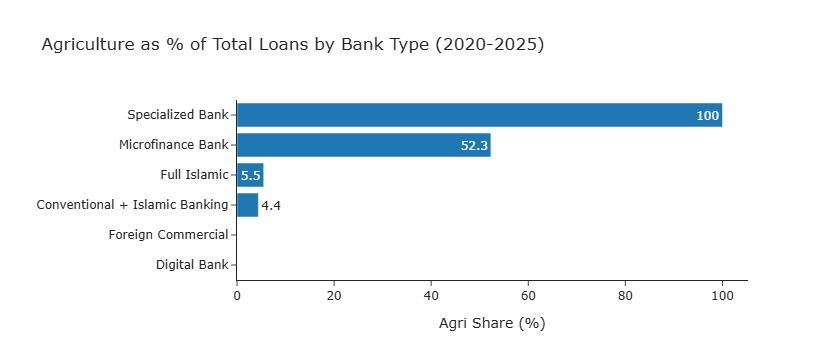

In [91]:
# Q2. Who serves the market: how much of each bank type's loans go to agriculture
by_type = bank_raw_df.groupby("Bank Type", as_index=False)[[gross_col, "Total Advances (PKR Bn)"]].sum()
by_type["Agri Share (%)"] = (by_type[gross_col] / by_type["Total Advances (PKR Bn)"] * 100).round(1)
by_type = by_type.sort_values("Agri Share (%)")

fig = px.bar(
    by_type,
    x="Agri Share (%)",
    y="Bank Type",
    orientation="h",
    text_auto=True,
    title="Agriculture as % of Total Loans by Bank Type (2020-2025)",
    labels={"Bank Type": ""}
)
fig.show()

### Q3. Where is demand concentrated?

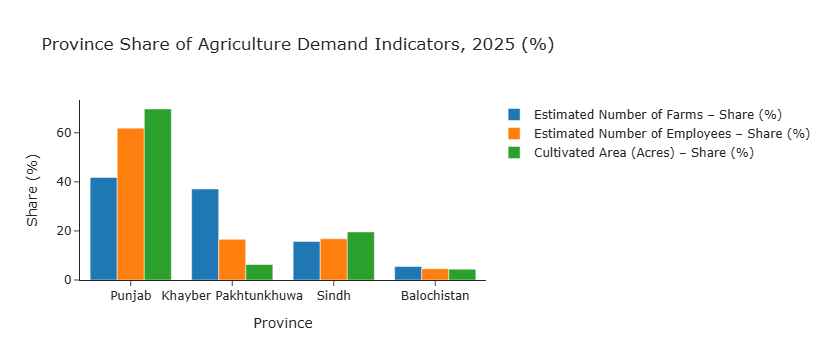

In [92]:
# Q3. Where demand is: province share of farms, workers and cultivated area
latest_prov = final_df[final_df["Year"] == latest_year]

fig = px.bar(
    latest_prov,
    x="Province",
    y=[
        "Estimated Number of Farms – Share (%)",
        "Estimated Number of Employees – Share (%)",
        "Cultivated Area (Acres) – Share (%)",
    ],
    barmode="group",
    title=f"Province Share of Agriculture Demand Indicators, {latest_year} (%)",
    labels={"value": "Share (%)", "variable": ""}
)
fig.show()

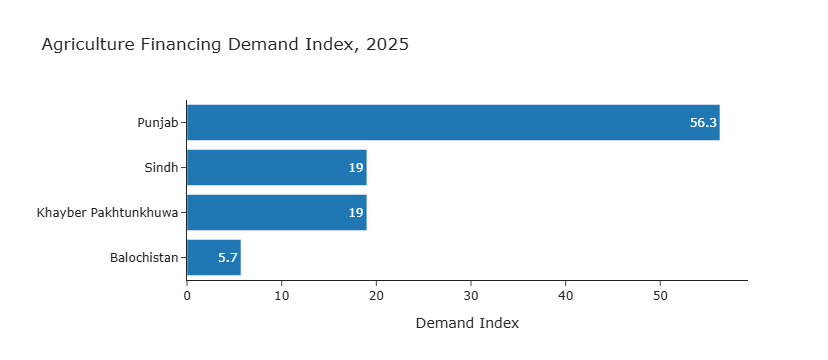

In [93]:
# Q3. Where demand is: Demand Index by province
latest_prov = final_df[final_df["Year"] == latest_year].sort_values("Demand Index")

fig = px.bar(
    latest_prov,
    x="Demand Index",
    y="Province",
    orientation="h",
    text_auto=True,
    title=f"Agriculture Financing Demand Index, {latest_year}",
    labels={"Province": ""}
)
fig.show()

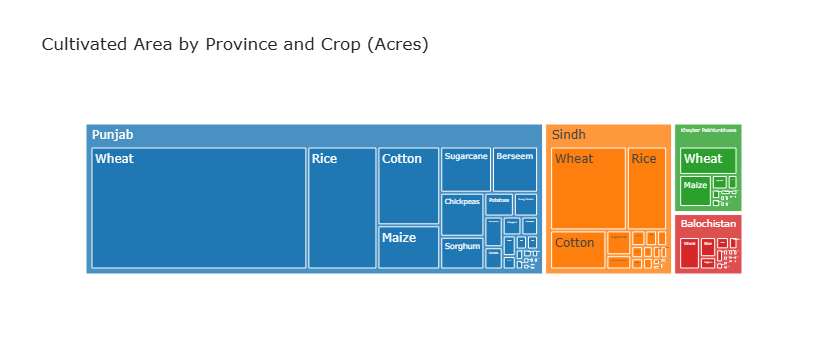

In [94]:
# Q3. Where demand is: cultivated area by province and crop
fig = px.treemap(
    crops_df,
    path=["Province", "Crop"],
    values="Cultivated Area (Acres)",
    title="Cultivated Area by Province and Crop (Acres)"
)
fig.show()

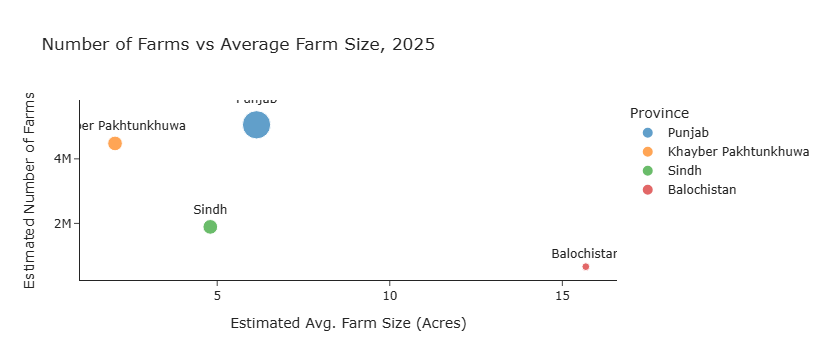

In [95]:
# Q3. Where demand is: number of farms and average farm size
latest_prov = final_df[final_df["Year"] == latest_year]

fig = px.scatter(
    latest_prov,
    x="Estimated Avg. Farm Size (Acres)",
    y="Estimated Number of Farms",
    size="Estimated Number of Employees",
    color="Province",
    text="Province",
    title=f"Number of Farms vs Average Farm Size, {latest_year}"
)
fig.update_traces(textposition="top center")
fig.show()

### Q4. Where can a DRB participate?

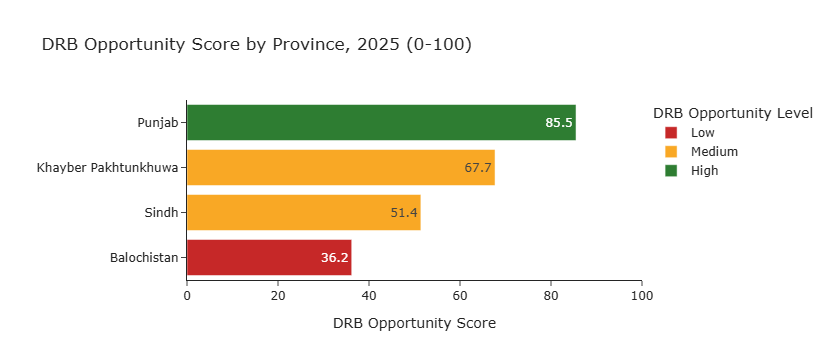

In [96]:
# Q4. DRB opportunity: score by province (latest year)
latest_prov = final_df[final_df["Year"] == latest_year].sort_values("DRB Opportunity Score")

fig = px.bar(
    latest_prov,
    x="DRB Opportunity Score",
    y="Province",
    color="DRB Opportunity Level",
    orientation="h",
    text_auto=True,
    title=f"DRB Opportunity Score by Province, {latest_year} (0-100)",
    labels={"Province": ""},
    color_discrete_map={"High": "#2E7D32", "Medium": "#F9A825", "Low": "#C62828"}
)
fig.update_layout(xaxis_range=[0, 100])
fig.show()

## Export the Processed Datasets

The processed data is exported as four CSV files, which serve as the data source for the Streamlit dashboard.

In [97]:
# ============================================================
# POWER BI FINAL DATASETS
# Ignore the previously created agri_final_data.csv
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. PROVINCE-LEVEL POWER BI TABLE
# ------------------------------------------------------------

# Start from original province data
province_pbi = agri_df.copy()

# Employee Growth
province_pbi = province_pbi.sort_values(["Province", "Year"])

province_pbi["Employee Growth (%)"] = (
    province_pbi
    .groupby("Province")["Estimated Number of Employees"]
    .pct_change() * 100
).round(2)

# Employees per Farm
province_pbi["Employees per Farm"] = (
    province_pbi["Estimated Number of Employees"] /
    province_pbi["Estimated Number of Farms"]
).round(2)

# Crop / Livestock / Fisheries output
province_pbi = province_pbi.merge(
    output_df[
        [
            "Province",
            "Crop Output (%)",
            "Livestock Output (%)",
            "Fisheries Output (%)"
        ]
    ],
    on="Province",
    how="left"
)

# Cultivated area by province
area_by_province = (
    crops_df
    .groupby("Province")["Cultivated Area (Acres)"]
    .sum()
)

province_pbi["Cultivated Area (Acres)"] = (
    province_pbi["Province"].map(area_by_province)
)

# ------------------------------------------------------------
# Province shares within each year
# ------------------------------------------------------------

province_pbi["Employees – Share (%)"] = (
    province_pbi["Estimated Number of Employees"] /
    province_pbi.groupby("Year")["Estimated Number of Employees"].transform("sum")
    * 100
).round(2)

province_pbi["Farms – Share (%)"] = (
    province_pbi["Estimated Number of Farms"] /
    province_pbi.groupby("Year")["Estimated Number of Farms"].transform("sum")
    * 100
).round(2)

province_pbi["Cultivated Area – Share (%)"] = (
    province_pbi["Cultivated Area (Acres)"] /
    province_pbi.groupby("Year")["Cultivated Area (Acres)"].transform("sum")
    * 100
).round(2)

# ------------------------------------------------------------
# Demand Index
# ------------------------------------------------------------

province_pbi["Demand Index"] = (
    province_pbi["Farms – Share (%)"] * 0.30 +
    province_pbi["Employees – Share (%)"] * 0.20 +
    province_pbi["Cultivated Area – Share (%)"] * 0.25 +
    province_pbi["Crop Output (%)"] * 0.25
).round(1)

province_pbi["Demand Rank"] = (
    province_pbi
    .groupby("Year")["Demand Index"]
    .rank(ascending=False)
    .astype(int)
)

# ------------------------------------------------------------
# DRB Opportunity Index
# ------------------------------------------------------------

higher_is_better = [
    "Estimated Number of Employees",
    "Agriculture – Provincial GDP Contribution (%)",
    "Agricultural Share of Employment (%)",
    "Estimated Number of Farms",
    "Cultivated Area (Acres)"
]

for col in higher_is_better:

    province_pbi[f"{col} Index"] = (
        province_pbi[col] /
        province_pbi.groupby("Year")[col].transform("max")
        * 100
    ).round(1)

# Smaller farms = higher opportunity score
small_farm = 1 / province_pbi["Estimated Avg. Farm Size (Acres)"]

province_pbi["Estimated Avg. Farm Size (Acres) Index"] = (
    small_farm /
    small_farm.groupby(province_pbi["Year"]).transform("max")
    * 100
).round(1)

# Equal weights across 6 factors
province_pbi["DRB Opportunity Score"] = (
    province_pbi["Estimated Number of Employees Index"] +
    province_pbi["Agriculture – Provincial GDP Contribution (%) Index"] +
    province_pbi["Agricultural Share of Employment (%) Index"] +
    province_pbi["Estimated Number of Farms Index"] +
    province_pbi["Estimated Avg. Farm Size (Acres) Index"] +
    province_pbi["Cultivated Area (Acres) Index"]
) / 6

province_pbi["DRB Opportunity Score"] = (
    province_pbi["DRB Opportunity Score"].round(1)
)

province_pbi["DRB Opportunity Level"] = pd.cut(
    province_pbi["DRB Opportunity Score"],
    bins=[0, 40, 70, 100],
    labels=["Low", "Medium", "High"],
    include_lowest=True
).astype(str)

province_pbi["DRB Rank"] = (
    province_pbi
    .groupby("Year")["DRB Opportunity Score"]
    .rank(ascending=False)
    .astype(int)
)

# ------------------------------------------------------------
# National disbursement per farm
# ------------------------------------------------------------

yearly_disbursement = (
    bank_df
    .groupby("Year")["Agricultural Credit Disbursement (PKR Bn)"]
    .sum()
)

yearly_farms = (
    province_pbi
    .groupby("Year")["Estimated Number of Farms"]
    .sum()
)

province_pbi["National Disbursement per Farm (PKR)"] = (
    province_pbi["Year"].map(
        yearly_disbursement * 1e9 / yearly_farms
    )
).round(0)

# ------------------------------------------------------------
# Select ONLY Power BI relevant columns
# ------------------------------------------------------------

province_columns = [
    "Year",
    "Province",
    "Population",
    "Estimated Number of Employees",
    "Employee Growth (%)",
    "Estimated Number of Farms",
    "Estimated Avg. Farm Size (Acres)",
    "Employees per Farm",
    "Agriculture – Provincial GDP Contribution (%)",
    "Agricultural Share of Employment (%)",
    "Crop Output (%)",
    "Livestock Output (%)",
    "Fisheries Output (%)",
    "Cultivated Area (Acres)",
    "Employees – Share (%)",
    "Farms – Share (%)",
    "Cultivated Area – Share (%)",
    "Demand Index",
    "Demand Rank",
    "DRB Opportunity Score",
    "DRB Opportunity Level",
    "DRB Rank",
    "National Disbursement per Farm (PKR)"
]

province_pbi = (
    province_pbi[province_columns]
    .sort_values(["Year", "DRB Rank"])
    .reset_index(drop=True)
)


# ============================================================
# 2. BANK-LEVEL POWER BI TABLE
# ============================================================

bank_pbi = bank_df.copy()

# Segment
bank_pbi["Segment"] = (
    bank_pbi["Bank Type"]
    .map({
        "Microfinance Bank": "MFB + Digital",
        "Digital Bank": "MFB + Digital"
    })
    .fillna("Commercial / Islamic / Specialized")
)

# Disbursement Market Share
bank_pbi["Disbursement Market Share (%)"] = (
    bank_pbi["Agricultural Credit Disbursement (PKR Bn)"] /
    bank_pbi.groupby("Year")[
        "Agricultural Credit Disbursement (PKR Bn)"
    ].transform("sum")
    * 100
).round(2)

# Agri Disbursement Share
bank_pbi["Agri Disbursement Share (%)"] = (
    bank_pbi["Agricultural Credit Disbursement (PKR Bn)"] /
    bank_pbi["Total Advances (PKR Bn)"]
    * 100
).round(2)

# Agri Gross Advances Share
bank_pbi["Agri Gross Advances Share (%)"] = (
    bank_pbi["Agriculture Gross Advances(PKR bn)"] /
    bank_pbi["Total Advances (PKR Bn)"]
    * 100
).round(2)

# Bank-wise YoY growth
bank_pbi = bank_pbi.sort_values(["Bank", "Year"])

bank_pbi["Disbursement Growth (%)"] = (
    bank_pbi
    .groupby("Bank")["Agricultural Credit Disbursement (PKR Bn)"]
    .pct_change() * 100
).round(2)

bank_pbi["Gross Advances Growth (%)"] = (
    bank_pbi
    .groupby("Bank")["Agriculture Gross Advances(PKR bn)"]
    .pct_change() * 100
).round(2)

# Rename for cleaner Power BI field names
bank_pbi = bank_pbi.rename(
    columns={
        "Agriculture Gross Advances(PKR bn)":
            "Agriculture Gross Advances (PKR Bn)"
    }
)

bank_columns = [
    "Year",
    "Bank",
    "Bank Type",
    "Segment",
    "Total Advances (PKR Bn)",
    "Agricultural Credit Disbursement (PKR Bn)",
    "Agriculture Gross Advances (PKR Bn)",
    "Disbursement Market Share (%)",
    "Agri Disbursement Share (%)",
    "Agri Gross Advances Share (%)"
]

bank_pbi = (
    bank_pbi[bank_columns]
    .sort_values(["Year", "Agricultural Credit Disbursement (PKR Bn)"],
                 ascending=[True, False])
    .reset_index(drop=True)
)


# ============================================================
# 3. CROP-LEVEL POWER BI TABLE
# ============================================================

crop_pbi = crops_df.copy()

# Province crop share
crop_pbi["Province Crop Share (%)"] = (
    crop_pbi["Cultivated Area (Acres)"] /
    crop_pbi.groupby("Province")[
        "Cultivated Area (Acres)"
    ].transform("sum")
    * 100
).round(2)

# National crop share
crop_pbi["National Crop Share (%)"] = (
    crop_pbi["Cultivated Area (Acres)"] /
    crop_pbi["Cultivated Area (Acres)"].sum()
    * 100
).round(2)

crop_pbi = crop_pbi[
    [
        "Province",
        "Crop",
        "Cultivated Area (Acres)",
        "Province Crop Share (%)",
        "National Crop Share (%)"
    ]
].sort_values(
    ["Province", "Cultivated Area (Acres)"],
    ascending=[True, False]
).reset_index(drop=True)


# ============================================================
# 4. MARKET-LEVEL POWER BI TABLE
# ============================================================

market_pbi = (
    bank_df
    .groupby("Year")
    .agg({
        "Total Advances (PKR Bn)": "sum",
        "Agricultural Credit Disbursement (PKR Bn)": "sum",
        "Agriculture Gross Advances(PKR bn)": "sum",
        "Bank": "nunique"
    })
    .reset_index()
)

market_pbi = market_pbi.rename(
    columns={
        "Agriculture Gross Advances(PKR bn)":
            "Agriculture Gross Advances (PKR Bn)",
        "Bank": "Number of Banks"
    }
)

# YoY growth
market_pbi["Disbursement YoY (%)"] = (
    market_pbi["Agricultural Credit Disbursement (PKR Bn)"]
    .pct_change() * 100
).round(2)

market_pbi["Gross Advances YoY (%)"] = (
    market_pbi["Agriculture Gross Advances (PKR Bn)"]
    .pct_change() * 100
).round(2)

# Agriculture share of total advances
market_pbi["Agri Share of Total Advances (%)"] = (
    market_pbi["Agriculture Gross Advances (PKR Bn)"] /
    market_pbi["Total Advances (PKR Bn)"]
    * 100
).round(2)


# ============================================================
# 5. EXPORT CLEAN CSV FILES
# ============================================================

province_pbi.to_csv(
    "Agri_Province_PowerBI.csv",
    index=False
)

bank_pbi.to_csv(
    "Agri_Bank_PowerBI.csv",
    index=False
)

crop_pbi.to_csv(
    "Agri_Crop_PowerBI.csv",
    index=False
)

market_pbi.to_csv(
    "Agri_Market_PowerBI.csv",
    index=False
)


# ============================================================
# 6. CHECK OUTPUTS
# ============================================================

print("Power BI files created successfully!")
print("-----------------------------------")

print(
    "Province:",
    province_pbi.shape,
    "-> Agri_Province_PowerBI.csv"
)

print(
    "Bank:",
    bank_pbi.shape,
    "-> Agri_Bank_PowerBI.csv"
)

print(
    "Crop:",
    crop_pbi.shape,
    "-> Agri_Crop_PowerBI.csv"
)

print(
    "Market:",
    market_pbi.shape,
    "-> Agri_Market_PowerBI.csv"
)

Power BI files created successfully!
-----------------------------------
Province: (24, 23) -> Agri_Province_PowerBI.csv
Bank: (234, 10) -> Agri_Bank_PowerBI.csv
Crop: (107, 5) -> Agri_Crop_PowerBI.csv
Market: (6, 8) -> Agri_Market_PowerBI.csv


#### Outcome

Four visualization-ready datasets were created:

| File | Rows | Columns | Content |
|------|------|---------|---------|
| Agri_Province_PowerBI.csv | 24 | 23 | Provincial profile, Demand Index and DRB score |
| Agri_Bank_PowerBI.csv | 234 | 10 | Bank-level lending and shares |
| Agri_Crop_PowerBI.csv | 107 | 5 | Cultivated area by province and crop |
| Agri_Market_PowerBI.csv | 6 | 8 | Yearly market totals and growth |

## Conclusion

This analysis assessed Pakistan's agricultural lending market to identify where a **Digital Retail Bank (DRB)** can participate.

- **Market size:** Agricultural disbursement more than doubled, from **PKR 1,183.8 billion (2020) to PKR 2,542.6 billion (2025)**, a **16.5% CAGR**. Its share of total bank advances stayed at around **7%**.
- **Who serves it:** Commercial banks dominate with **78.5%**, led by HBL and NBP, while **digital banks hold only 0.05%**.
- **Where demand is:** **Punjab** is the largest market, while **Khyber Pakhtunkhwa** holds 37.1% of farms on just 6.3% of cultivated area, a large base of very small farms.
- **DRB opportunity:** Punjab scores highest (**85.5**), but **Khyber Pakhtunkhwa (67.7)** is the best fit for a digital model due to its small farms, rising score and full Risk Coverage Scheme eligibility.

**Recommendation:** A DRB should enter through **Khyber Pakhtunkhwa** with small-ticket digital crop and livestock loans, then expand into **Punjab**, using Zarkhez-e, satellite verification and the Risk Coverage Scheme to lower risk and cost.

*Note: Provincial demand is based on estimated proxy indicators, and all values are nominal.*